# S&P 500 sectors: return per unit of volatility, 2010-2024

**Question:** which sectors gave the best return for the volatility taken, and did it hold in each 5-year sub-period?

**What this notebook does**
1. Loads the Databricks exports (weekly sector returns, the dbt mart, and per-ticker price coverage).
2. Checks how much of the index has prices, and whether the missing companies follow a pattern.
3. Recomputes annualised return, volatility and return per volatility in pandas, and reconciles against the mart. The notebook stops if they disagree.
4. Measures how uncertain each ratio is, and tests which changes between periods are bigger than that uncertainty.
5. Draws one chart.

**Read before using any number**
- Only 172 of 502 companies have prices. The Kaggle source file has no prices at all for the other 330. Section 2 shows the gaps are scattered and even across company sizes, so the 172 behave like a random third of the index. Big names such as Apple, JPMorgan and ExxonMobil are among the missing.
- Constituents are today's, so survivorship bias inflates absolute returns. Use the numbers to compare sectors only.
- Sector returns are an equal-weighted average of weekly close-to-close returns, which assumes weekly rebalancing.
- `return_per_volatility` is return divided by volatility. There is no risk-free rate, so it is not a Sharpe ratio.
- The set of stocks in a sector changes between sub-periods (late listings such as TSLA, META, UBER).
- This is a description of the past. It is not a forecast or investment advice.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# "databricks" reads the live dbt tables. "csv" reads the committed snapshots in data/.
SOURCE = "csv"                      # change to "databricks" when you have the connection set up
SAVE_SNAPSHOT = False               # True: after a live read, overwrite the CSV snapshots in data/

WEEKLY_TABLE = "stocks.sp500_dev_marts.fct_sector_weekly_returns"
MART_TABLE = "stocks.sp500_dev_marts.mart_sector_risk_return"
WEEKLY_CSV = Path("../data/fct_sector_weekly_returns.csv")
MART_CSV = Path("../data/mart_sector_risk_return.csv")
# Per-ticker price coverage. Rebuild it with analyses/ticker_coverage.sql (dbt compile, then run in Databricks).
COVERAGE_CSV = Path("../data/ticker_coverage.csv")

WEEKS_PER_YEAR = 52
THIN_BELOW = 10          # sectors with fewer stocks than this are labelled thin
TOL = 1e-9               # reconciliation tolerance for return, volatility, ratio
SUB_PERIODS = ["2010-2014", "2015-2019", "2020-2024"]

# Bootstrap settings for the uncertainty section
N_BOOT = 2000            # resamples per sector and period
BLOCK_WEEKS = 8          # resample 8-week blocks so short runs of related weeks stay together
SEED = 42                # fixed, so the notebook gives the same numbers every run

## 1. Load and check the inputs

In [2]:
NUMERIC_WEEKLY = ["sector_weekly_return", "ticker_count"]
NUMERIC_MART = ["weeks", "avg_tickers", "annualised_return", "annualised_volatility", "return_per_volatility"]


def read_table(table):
    # Connection details come from environment variables. Never write them in the notebook.
    from databricks import sql
    with sql.connect(
        server_hostname=os.environ["DATABRICKS_HOST"],
        http_path=os.environ["DATABRICKS_HTTP_PATH"],
        access_token=os.environ["DATABRICKS_TOKEN"],
    ) as conn:
        with conn.cursor() as cur:
            cur.execute(f"SELECT * FROM {table}")
            return cur.fetchall_arrow().to_pandas()


if SOURCE == "databricks":
    weekly = read_table(WEEKLY_TABLE)
    mart = read_table(MART_TABLE)
elif SOURCE == "csv":
    weekly = pd.read_csv(WEEKLY_CSV)
    mart = pd.read_csv(MART_CSV)
else:
    raise ValueError(f"SOURCE must be 'databricks' or 'csv', got {SOURCE!r}")

# Live reads can return Decimal types, so force plain numbers.
weekly[NUMERIC_WEEKLY] = weekly[NUMERIC_WEEKLY].astype(float)
mart[NUMERIC_MART] = mart[NUMERIC_MART].astype(float)

# CSV exports store dates as 2010-01-11T00:00:00.000Z. Parse, then drop the timezone.
weekly["week_start_date"] = pd.to_datetime(weekly["week_start_date"], utc=True).dt.tz_localize(None)
weekly = weekly.sort_values(["business_sector", "week_start_date"]).reset_index(drop=True)
mart = mart.sort_values(["business_sector", "sub_period"]).reset_index(drop=True)

# Snapshot guards: these counts match the committed CSVs (8,580 sector-weeks = 11 sectors x 780 weeks;
# 44 mart rows = 11 sectors x 4 periods). Update them on purpose if the models change.
assert len(weekly) == 8580, len(weekly)
assert len(mart) == 44, len(mart)
assert weekly.isna().sum().sum() == 0, "nulls in weekly table"
assert not weekly.duplicated(["business_sector", "week_start_date"]).any(), "duplicate sector-weeks"
assert weekly["business_sector"].nunique() == 11

print("Source:", SOURCE)
print(weekly["week_start_date"].min().date(), "to", weekly["week_start_date"].max().date())
weekly.head()

Source: csv
2010-01-11 to 2024-12-16


,business_sector,week_start_date,sector_weekly_return,ticker_count
0,Basic Materials,2010-01-11,-0.016036,7.0
1,Basic Materials,2010-01-18,-0.045635,7.0
2,Basic Materials,2010-01-25,-0.024026,7.0
3,Basic Materials,2010-02-01,0.014163,7.0
4,Basic Materials,2010-02-08,0.023535,7.0


### 1b. Live data vs the committed snapshot
Only runs when `SOURCE = "databricks"`. It shows whether the models changed since the snapshot was taken.
If they differ, the memo and dashboard numbers need re-checking.

In [3]:
if SOURCE == "databricks":
    if WEEKLY_CSV.exists() and MART_CSV.exists():
        snap_w = pd.read_csv(WEEKLY_CSV)
        snap_w["week_start_date"] = pd.to_datetime(snap_w["week_start_date"], utc=True).dt.tz_localize(None)
        snap_w = snap_w.sort_values(["business_sector", "week_start_date"]).reset_index(drop=True)
        snap_m = pd.read_csv(MART_CSV).sort_values(["business_sector", "sub_period"]).reset_index(drop=True)

        w_diff = (weekly["sector_weekly_return"] - snap_w["sector_weekly_return"]).abs().max()
        m_diff = (mart["return_per_volatility"] - snap_m["return_per_volatility"]).abs().max()
        same_keys = (weekly[["business_sector", "week_start_date"]].equals(snap_w[["business_sector", "week_start_date"]])
                     and mart[["business_sector", "sub_period"]].equals(snap_m[["business_sector", "sub_period"]]))
        print("Same sectors and weeks as snapshot:", same_keys)
        print(f"Largest weekly-return difference vs snapshot: {w_diff:.3e}")
        print(f"Largest ratio difference vs snapshot:         {m_diff:.3e}")
    else:
        print("No snapshot found to compare against.")

    if SAVE_SNAPSHOT:
        WEEKLY_CSV.parent.mkdir(parents=True, exist_ok=True)
        weekly.to_csv(WEEKLY_CSV, index=False)
        mart.to_csv(MART_CSV, index=False)
        print("Snapshots overwritten.")
else:
    print("SOURCE is csv, nothing to compare.")

SOURCE is csv, nothing to compare.


## 2. How much of the index has prices?
The Kaggle file has a row for every ticker on every trading day (502 x 3,768 = 1,891,536 rows), but 330 tickers are empty on every day.
If the missing companies were mostly large, or mostly from one part of the alphabet, the results would be biased. This section checks.

In [4]:
cov = pd.read_csv(COVERAGE_CSV)
assert len(cov) == 502 and cov["company_ticker"].is_unique
cov["has_prices"] = cov["price_days"] > 0

n_have = int(cov["has_prices"].sum())
weight_have = cov.loc[cov["has_prices"], "index_weight"].sum() / cov["index_weight"].sum()
print(f"Companies with prices: {n_have} of {len(cov)} ({n_have / len(cov):.0%})")
print(f"Share of index weight covered: {weight_have:.0%}")

# Coverage by size band (rank by index weight, 1 = largest)
cov["size_rank"] = cov["index_weight"].rank(ascending=False, method="first").astype(int)
cov["size_band"] = pd.cut(cov["size_rank"], [0, 100, 200, 300, 400, 502],
                          labels=["1-100", "101-200", "201-300", "301-400", "401-502"])
by_size = cov.groupby("size_band", observed=True)["has_prices"].agg(have="sum", companies="count")
by_size["share"] = (by_size["have"] / by_size["companies"]).round(2)
display(by_size)

by_sector = cov.groupby("business_sector")["has_prices"].agg(have="sum", companies="count")
by_sector["share"] = (by_sector["have"] / by_sector["companies"]).round(2)
display(by_sector.sort_values("companies", ascending=False))

# Chi-square test: is the share with prices the same in every sector?
from scipy.stats import chi2_contingency
p_sector = chi2_contingency(np.array([by_sector["have"], by_sector["companies"] - by_sector["have"]]))[1]
p_size = chi2_contingency(np.array([by_size["have"], by_size["companies"] - by_size["have"]]))[1]
print(f"Chance of sector differences this big if gaps were random: p = {p_sector:.2f}")
print(f"Chance of size-band differences this big if gaps were random: p = {p_size:.2f}")

top20 = cov.nsmallest(20, "size_rank")
print("Largest 20 companies missing prices:", top20.loc[~top20["has_prices"], "company_ticker"].tolist())

# Partial history = listed after 2010 (normal). Empty = missing from the source (not normal).
partial = cov[(cov["price_days"] > 0) & (cov["price_days"] < cov["price_days"].max())]
print(f"Tickers with partial history (listed after 2010-01-04): {len(partial)}, "
      f"for example {partial.sort_values('first_price_date')['company_ticker'].head(5).tolist()}")

Companies with prices: 172 of 502 (34%)
Share of index weight covered: 45%


,have,companies,share
size_band,,,
1-100,35,100,0.35
101-200,33,100,0.33
201-300,34,100,0.34
301-400,39,100,0.39
401-502,31,102,0.30


,have,companies,share
business_sector,,,
Technology,23,82,0.28
Industrials,27,70,0.39
Financial Services,25,67,0.37
Healthcare,21,62,0.34
Consumer Cyclical,18,55,0.33
Consumer Defensive,12,37,0.32
Utilities,9,32,0.28
Real Estate,13,31,0.42
Basic Materials,7,22,0.32


Chance of sector differences this big if gaps were random: p = 0.52
Chance of size-band differences this big if gaps were random: p = 0.78
Largest 20 companies missing prices: ['AAPL', 'GOOGL', 'AVGO', 'BRK-B', 'WMT', 'LLY', 'JPM', 'MA', 'XOM', 'UNH', 'COST', 'PG']
Tickers with partial history (listed after 2010-01-04): 22, for example ['TSLA', 'HCA', 'HII', 'XYL', 'ENPH']


**Reading the coverage checks**
- About a third of companies have prices in every size band and in every sector, and the chi-square tests find no pattern. The missing tickers are not the biggest, not the smallest, and not one sector.
- The most likely cause is a failed bulk download from Yahoo Finance when the Kaggle dataset was last updated: whole tickers came back empty.
- So the 172 stocks work as a random third of the index. Sector comparisons are thin, but not biased by size or sector. Treat them as "these 172 stocks", not "the S&P 500".

## 3. Recompute in pandas

In [5]:
year = weekly["week_start_date"].dt.year
weekly["sub_period"] = np.select(
    [year <= 2014, year <= 2019], SUB_PERIODS[:2], default=SUB_PERIODS[2]
)
weekly["log_ret"] = np.log1p(weekly["sector_weekly_return"])


def summarise(df, keys):
    # Named aggregations instead of groupby().apply(), which warns in newer pandas.
    out = df.groupby(keys).agg(
        weeks=("log_ret", "size"),
        avg_tickers=("ticker_count", "mean"),
        mean_log=("log_ret", "mean"),
        sd_log=("log_ret", "std"),          # sample std (ddof=1), same as Spark stddev
    ).reset_index()
    out["annualised_return"] = np.exp(out["mean_log"] * WEEKS_PER_YEAR) - 1
    out["annualised_volatility"] = out["sd_log"] * np.sqrt(WEEKS_PER_YEAR)
    out["return_per_volatility"] = out["annualised_return"] / out["annualised_volatility"]
    return out.drop(columns=["mean_log", "sd_log"])


by_period = summarise(weekly, ["business_sector", "sub_period"])
full = summarise(weekly, ["business_sector"]).assign(sub_period="full")
calc = pd.concat([by_period, full], ignore_index=True)
calc.shape

(44, 7)

## 3. Reconcile against the dbt mart

In [6]:
chk = calc.merge(mart, on=["business_sector", "sub_period"], suffixes=("_pd", "_mart"), validate="one_to_one")
assert len(chk) == 44, "rows did not match one-to-one"

report = {}
for col in ["annualised_return", "annualised_volatility", "return_per_volatility"]:
    report[col] = (chk[f"{col}_pd"] - chk[f"{col}_mart"]).abs().max()
report["weeks"] = (chk["weeks_pd"] - chk["weeks_mart"]).abs().max()
# The mart stores avg_tickers as a whole number, so allow rounding (0.5).
report["avg_tickers (rounded in mart)"] = (chk["avg_tickers_pd"] - chk["avg_tickers_mart"]).abs().max()

print("Largest absolute difference, pandas vs mart")
for k, v in report.items():
    print(f"  {k:32s} {v:.3e}")

assert report["annualised_return"] < TOL
assert report["annualised_volatility"] < TOL
assert report["return_per_volatility"] < TOL
assert report["weeks"] == 0
assert report["avg_tickers (rounded in mart)"] <= 0.5
print("\nRECONCILED: pandas matches the mart.")

Largest absolute difference, pandas vs mart
  annualised_return                8.882e-16
  annualised_volatility            3.608e-16
  return_per_volatility            4.663e-15
  weeks                            0.000e+00
  avg_tickers (rounded in mart)    4.962e-01

RECONCILED: pandas matches the mart.


## 5. Ratios and ranks by sub-period
Rank 1 = best return per volatility. Thin sectors (fewer than 10 stocks) are flagged.
Section 6 tests which of these differences are bigger than the noise. Ranks alone make small gaps look large.

In [7]:
ratio = calc.pivot(index="business_sector", columns="sub_period", values="return_per_volatility")
ratio = ratio[SUB_PERIODS + ["full"]]
ranks = ratio.rank(ascending=False).astype(int)
stocks = calc[calc["sub_period"] == "full"].set_index("business_sector")["avg_tickers"].round().astype(int)

summary = ratio.round(2).join(ranks.add_suffix("_rank"))
summary["stocks"] = stocks
summary["thin"] = summary["stocks"] < THIN_BELOW
display(summary.sort_values("full", ascending=False))

winners = ratio[SUB_PERIODS].idxmax()
print("Best sector per sub-period:", winners.to_dict())
print("Any sector best in all three?", winners.nunique() == 1)

top5_all = (ranks[SUB_PERIODS] <= 5).all(axis=1)
print("Sectors in the top 5 of 11 in all three sub-periods:", list(top5_all[top5_all].index))
print("Negative ratio in any sub-period:",
      ratio[SUB_PERIODS].stack().loc[lambda s: s < 0].round(3).to_dict())

sub_period,2010-2014,2015-2019,2020-2024,full,2010-2014_rank,2015-2019_rank,2020-2024_rank,full_rank,stocks,thin
business_sector,,,,,,,,,,
Technology,0.71,1.23,1.07,0.98,11,1,1,1,21,False
Communication Services,1.42,1.15,0.48,0.97,3,2,7,2,11,False
Healthcare,1.48,1.06,0.49,0.95,2,3,6,3,20,False
Consumer Cyclical,1.40,1.02,0.63,0.93,4,5,5,4,18,False
Industrials,1.16,1.06,0.70,0.92,6,4,2,5,25,False
Consumer Defensive,1.82,1.00,0.23,0.91,1,6,10,6,12,False
Financial Services,0.99,0.84,0.63,0.77,8,7,4,7,25,False
Real Estate,1.18,0.81,0.34,0.66,5,8,8,8,13,False
Utilities,0.99,0.76,0.22,0.54,7,9,11,9,9,True


Best sector per sub-period: {'2010-2014': 'Consumer Defensive', '2015-2019': 'Technology', '2020-2024': 'Technology'}
Any sector best in all three? False
Sectors in the top 5 of 11 in all three sub-periods: ['Consumer Cyclical']
Negative ratio in any sub-period: {('Energy', '2015-2019'): -0.052}


## 6. How uncertain is each ratio?
A 5-year ratio from weekly data is noisy. Two ways to measure that noise:
- **Formula:** the standard approximation for a return/volatility ratio, `sqrt((1 + ratio^2 / 2) / years)`. It assumes weekly returns are independent and normally distributed.
- **Block bootstrap:** resample the actual weekly returns in 8-week blocks 2,000 times, recompute the ratio each time, and see how much it moves. It makes fewer assumptions, so it is the one used for the conclusions.

In [8]:
rng = np.random.default_rng(SEED)


def ratio_from_logs(x):
    # x: 2-D array (resamples x weeks) of weekly log returns -> ratio per resample
    ret = np.exp(x.mean(axis=1) * WEEKS_PER_YEAR) - 1
    vol = x.std(axis=1, ddof=1) * np.sqrt(WEEKS_PER_YEAR)
    return ret / vol


def block_bootstrap(x, n_boot=N_BOOT, block=BLOCK_WEEKS):
    n = len(x)
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(n_boot, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    return ratio_from_logs(x[idx])


years = {sp: 5 for sp in SUB_PERIODS} | {"full": 15}
boot = {}          # (sector, period) -> array of bootstrapped ratios
rows = []
for (sector, period), g in pd.concat([weekly, weekly.assign(sub_period="full")]).groupby(["business_sector", "sub_period"]):
    x = g.sort_values("week_start_date")["log_ret"].to_numpy()
    b = block_bootstrap(x)
    boot[(sector, period)] = b
    r = ratio.loc[sector, period]
    rows.append({"business_sector": sector, "sub_period": period, "ratio": r,
                 "se_formula": np.sqrt((1 + r**2 / 2) / years[period]),
                 "se_bootstrap": b.std(ddof=1),
                 "ci_low": np.percentile(b, 2.5), "ci_high": np.percentile(b, 97.5)})
unc = pd.DataFrame(rows)

for label, mask in [("5-year sub-periods", unc["sub_period"] != "full"), ("Full 15 years", unc["sub_period"] == "full")]:
    u = unc[mask]
    print(f"{label}: formula SE {u['se_formula'].min():.2f}-{u['se_formula'].max():.2f}, "
          f"bootstrap SE {u['se_bootstrap'].min():.2f}-{u['se_bootstrap'].max():.2f}")

full_unc = unc[unc["sub_period"] == "full"].set_index("business_sector").sort_values("ratio", ascending=False)
display(full_unc[["ratio", "se_bootstrap", "ci_low", "ci_high"]].round(2))

5-year sub-periods: formula SE 0.45-0.73, bootstrap SE 0.41-0.61
Full 15 years: formula SE 0.27-0.31, bootstrap SE 0.26-0.33


,ratio,se_bootstrap,ci_low,ci_high
business_sector,,,,
Technology,0.98,0.31,0.47,1.68
Communication Services,0.97,0.31,0.41,1.65
Healthcare,0.95,0.30,0.45,1.62
Consumer Cyclical,0.93,0.33,0.37,1.66
Industrials,0.92,0.31,0.38,1.63
Consumer Defensive,0.91,0.27,0.41,1.48
Financial Services,0.77,0.32,0.26,1.48
Real Estate,0.66,0.28,0.22,1.31
Utilities,0.54,0.26,0.13,1.17


### 6b. Which changes between periods are real?
For each sector, compare 2010-2014 with 2020-2024 and take the 95% bootstrap range of the change. If the range does not include zero, the change is bigger than the noise.
With 11 sectors tested, about one could pass by chance, so the 99.5% range (95% split across 11 tests) is shown as a stricter check.

In [9]:
first, last = SUB_PERIODS[0], SUB_PERIODS[-1]
chg_rows = []
for sector in ratio.index:
    d = boot[(sector, last)] - boot[(sector, first)]   # independent resamples of two separate periods
    chg_rows.append({"business_sector": sector,
                     first: ratio.loc[sector, first], last: ratio.loc[sector, last],
                     "change": ratio.loc[sector, last] - ratio.loc[sector, first],
                     "ci95_low": np.percentile(d, 2.5), "ci95_high": np.percentile(d, 97.5),
                     "ci995_low": np.percentile(d, 0.25), "ci995_high": np.percentile(d, 99.75)})
chg = pd.DataFrame(chg_rows).set_index("business_sector").sort_values("change")
chg["real_at_95"] = (chg["ci95_low"] > 0) | (chg["ci95_high"] < 0)
chg["real_at_99_5"] = (chg["ci995_low"] > 0) | (chg["ci995_high"] < 0)
display(chg.round(2))

real_changes = chg.index[chg["real_at_95"]].tolist()
print("Changes bigger than the noise (95%):", real_changes)
print("Still bigger than the noise after allowing for 11 tests (99.5%):", chg.index[chg["real_at_99_5"]].tolist())

,2010-2014,2020-2024,change,ci95_low,ci95_high,ci995_low,ci995_high,real_at_95,real_at_99_5
business_sector,,,,,,,,,
Consumer Defensive,1.82,0.23,-1.59,-2.82,-0.36,-3.27,0.08,True,False
Healthcare,1.48,0.49,-0.99,-2.59,0.44,-3.28,1.12,False,False
Communication Services,1.42,0.48,-0.94,-2.66,0.55,-3.44,1.25,False,False
Real Estate,1.18,0.34,-0.85,-2.11,0.41,-2.52,0.89,False,False
Consumer Cyclical,1.40,0.63,-0.78,-2.29,0.86,-2.99,1.56,False,False
Utilities,0.99,0.22,-0.77,-1.91,0.47,-2.36,0.92,False,False
Basic Materials,0.83,0.27,-0.56,-1.97,0.91,-2.58,1.64,False,False
Industrials,1.16,0.70,-0.46,-1.89,1.04,-2.52,1.72,False,False
Financial Services,0.99,0.63,-0.36,-1.77,1.20,-2.34,1.86,False,False


Changes bigger than the noise (95%): ['Consumer Defensive']
Still bigger than the noise after allowing for 11 tests (99.5%): []


**What the uncertainty checks show**
- A 5-year ratio is uncertain by about 0.4 to 0.6 (bootstrap standard error 0.41 to 0.61; the formula gives 0.45 to 0.73). A 15-year ratio is uncertain by about 0.3.
- **Full period:** the top six sectors (0.91 to 0.98) have overlapping 95% ranges of roughly 0.4 to 1.7. Their ranking is noise.
- **Changes over time:** only Consumer Defensive's fall from 1.82 (2010-14) to 0.23 (2020-24) is bigger than the noise at 95% (range of the change: -2.82 to -0.36).
- It does **not** pass the stricter check that allows for testing 11 sectors (99.5% range -3.27 to +0.08). And the comparison was picked after looking at the chart. So treat it as a strong lead, not proof.
- Healthcare (-0.99) and Communication Services (-0.94) look like big drops, but both ranges include zero. Technology's move from 11th to 1st is a +0.37 change, well inside the noise. Ranks make small differences look large.

## 7. Chart
One small panel per sector, sorted by full-period ratio. Each dot is a 5-year ratio, and the vertical line is its 95% bootstrap range.
Sectors whose first-to-last change is bigger than the noise are drawn in blue; the rest are grey.

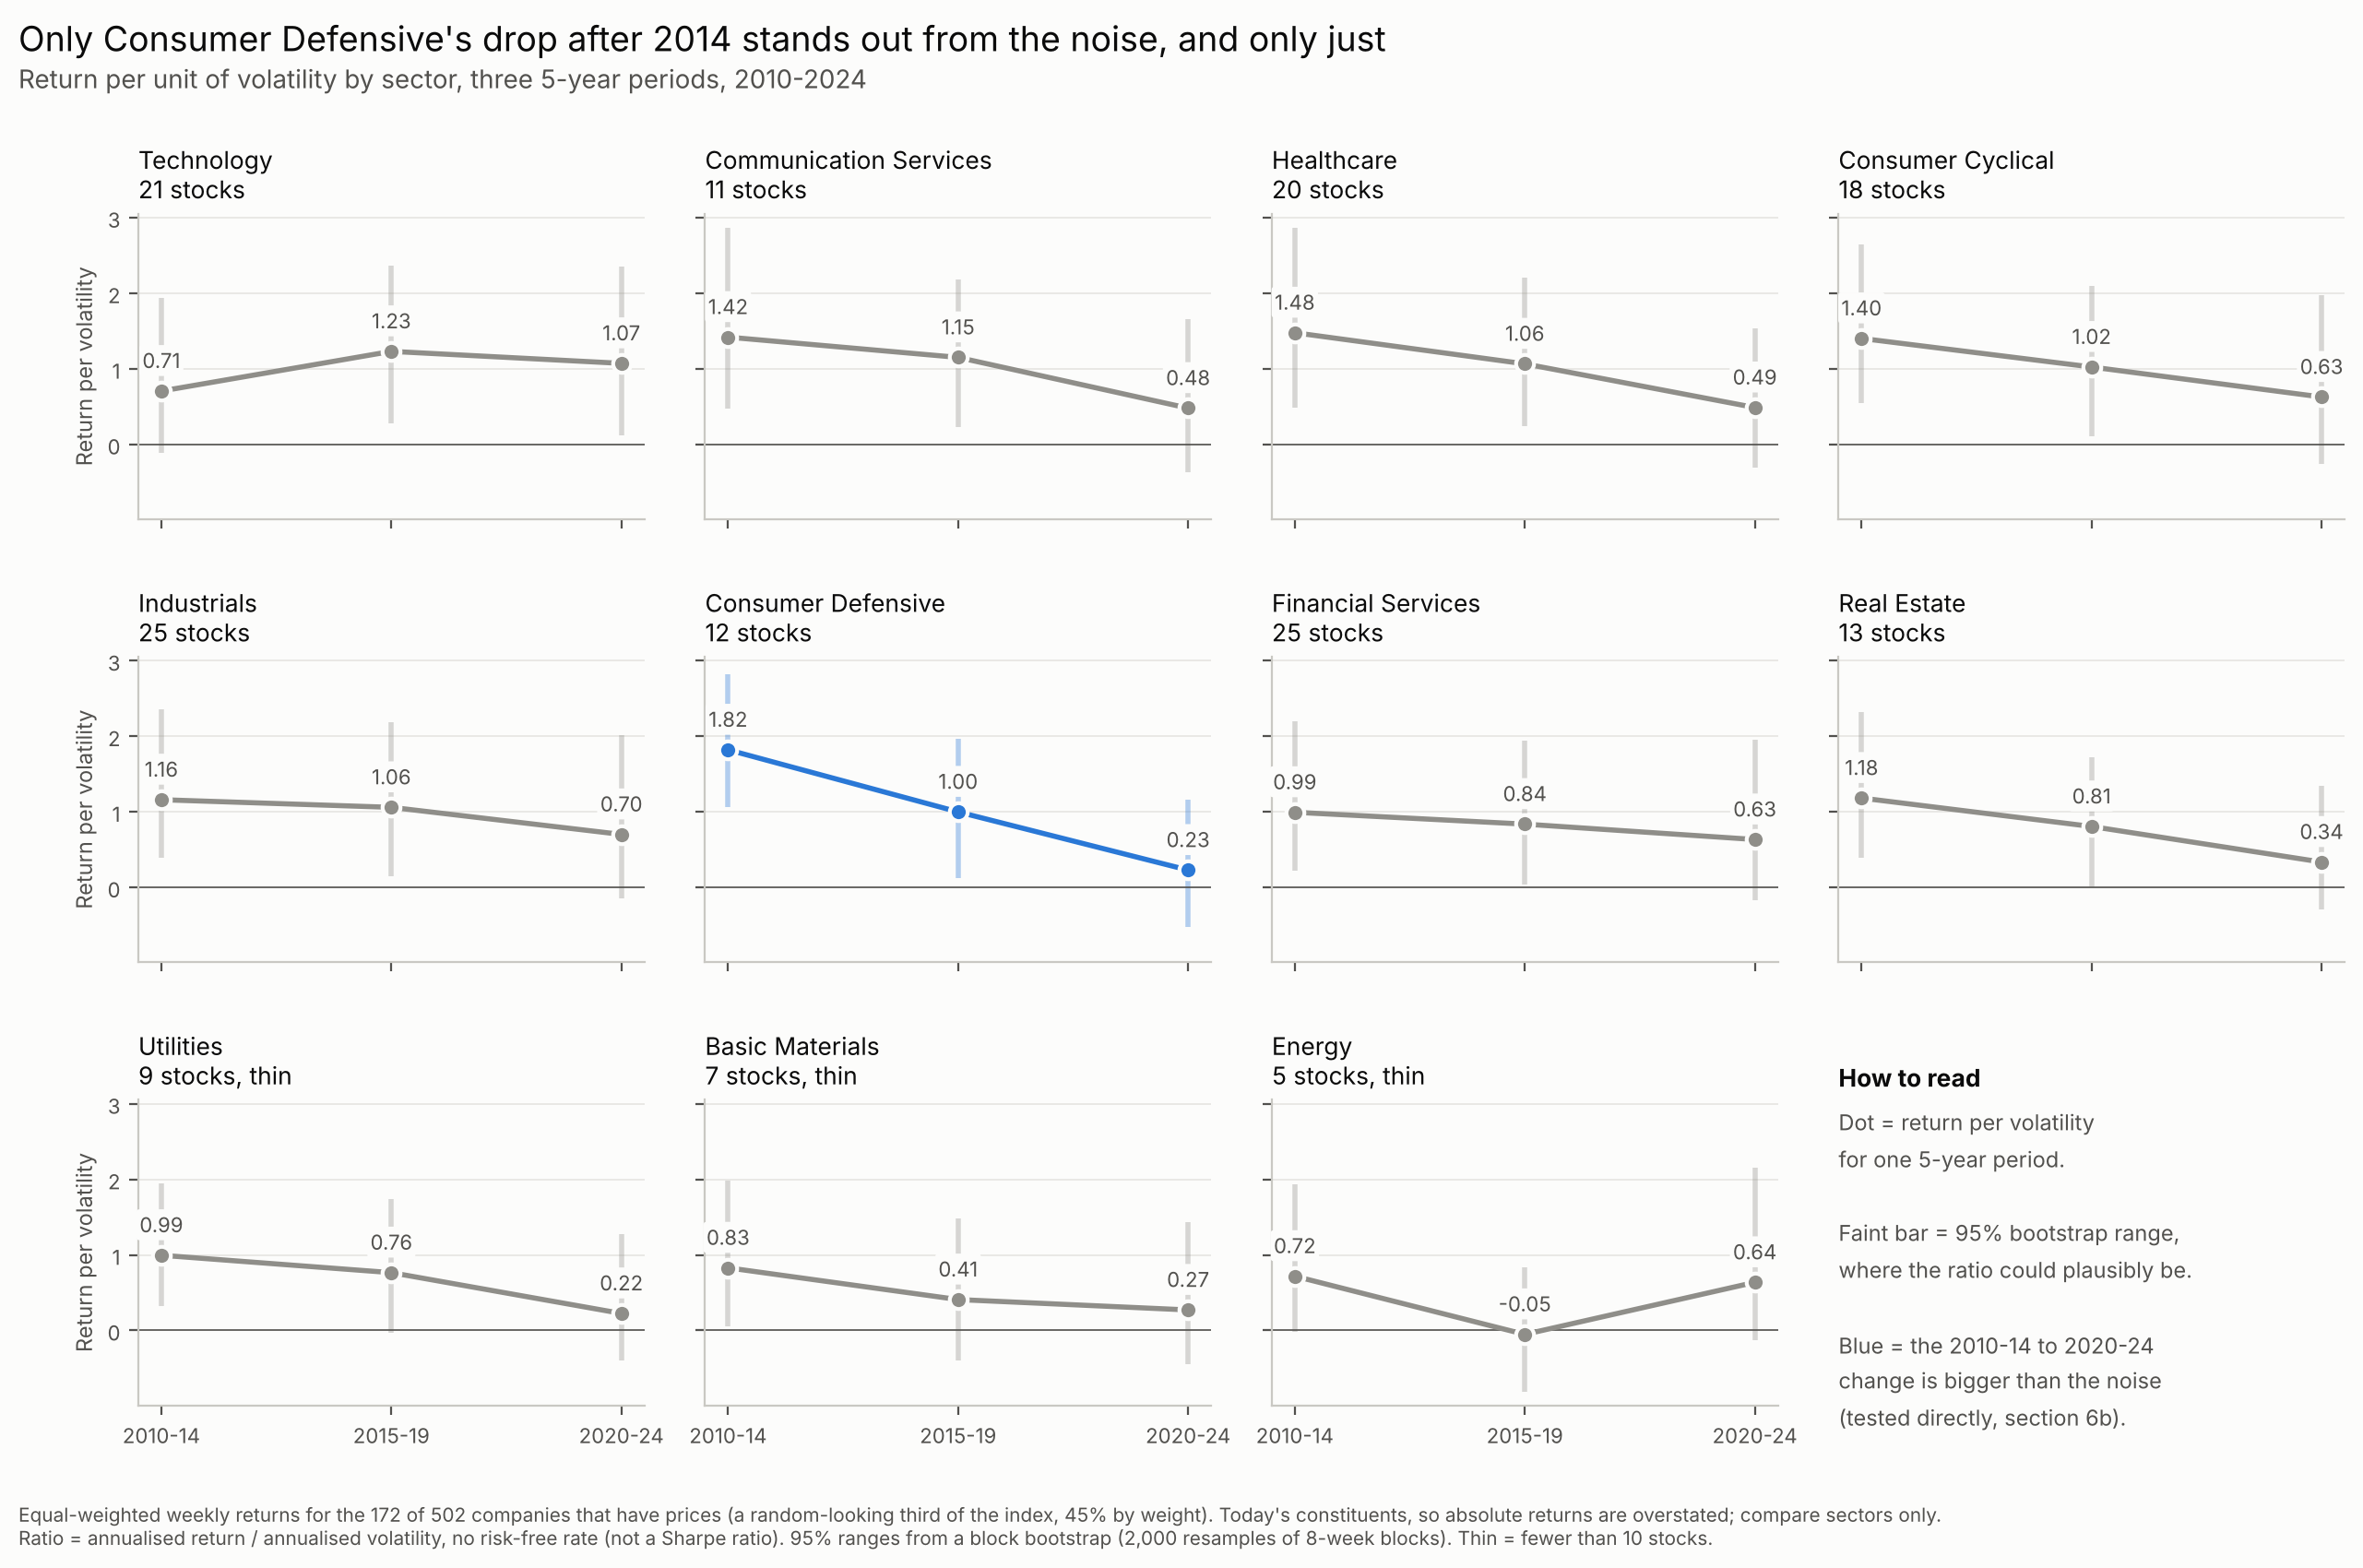

In [10]:
BLUE, GREY, INK, MUTED, SURFACE = "#2a78d6", "#8f8e89", "#0b0b0b", "#52514e", "#fcfcfb"

order = ratio["full"].sort_values(ascending=False).index.tolist()
ci = unc.set_index(["business_sector", "sub_period"])
x = np.arange(len(SUB_PERIODS))

fig, axes = plt.subplots(3, 4, figsize=(13, 8.5), sharex=True, sharey=True, facecolor=SURFACE)
for ax, sector in zip(axes.flat, order):
    colour = BLUE if sector in real_changes else GREY
    vals = ratio.loc[sector, SUB_PERIODS].to_numpy()
    lo = np.array([ci.loc[(sector, sp), "ci_low"] for sp in SUB_PERIODS])
    hi = np.array([ci.loc[(sector, sp), "ci_high"] for sp in SUB_PERIODS])
    ax.vlines(x, lo, hi, color=colour, linewidth=2, alpha=0.35)
    ax.plot(x, vals, color=colour, linewidth=2, marker="o", markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
    for xi, v in zip(x, vals):
        ax.annotate(f"{v:.2f}", (xi, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8,
                    color=MUTED, zorder=4, bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none"))
    ax.axhline(0, color=MUTED, linewidth=0.6)
    thin = ", thin" if stocks[sector] < THIN_BELOW else ""
    ax.set_title(f"{sector}\n{stocks[sector]} stocks{thin}", fontsize=9.5, color=INK, loc="left")
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c9c8c3")
    ax.tick_params(colors=MUTED, labelsize=8)

# The 12th panel holds the key instead of a legend box over the data.
key = axes.flat[-1]
key.axis("off")
key.text(0, 1.12, "How to read", fontsize=9.5, color=INK, weight="bold", va="top", transform=key.transAxes)
key.text(0, 0.98,
         "Dot = return per volatility\nfor one 5-year period.\n\n"
         "Faint bar = 95% bootstrap range,\nwhere the ratio could plausibly be.\n\n"
         "Blue = the 2010-14 to 2020-24\nchange is bigger than the noise\n(tested directly, section 6b).",
         fontsize=8.5, color=MUTED, va="top", transform=key.transAxes, linespacing=1.4)

for ax in axes[-1]:
    ax.set_xticks(x)
    ax.set_xticklabels(["2010-14", "2015-19", "2020-24"])
for ax in axes[:, 0]:
    ax.set_ylabel("Return per volatility", fontsize=8.5, color=MUTED)

strict = chg.index[chg["real_at_99_5"]].tolist()
if len(real_changes) == 1 and not strict:
    headline = f"Only {real_changes[0]}'s drop after 2014 stands out from the noise, and only just"
elif len(real_changes) == 1:
    headline = f"{real_changes[0]} lost its edge after 2014; other sector changes are within noise"
elif real_changes:
    headline = f"{', '.join(real_changes)} changed after 2014; other sector changes are within noise"
else:
    headline = "No sector's change after 2014 is bigger than the noise"
fig.suptitle(headline, x=0.01, y=0.985, ha="left", fontsize=13.5, color=INK)
fig.text(0.01, 0.94, "Return per unit of volatility by sector, three 5-year periods, 2010-2024",
         fontsize=10, color=MUTED)
fig.text(0.01, 0.008,
         f"Equal-weighted weekly returns for the {n_have} of 502 companies that have prices (a random-looking third of the index, "
         f"{weight_have:.0%} by weight). Today's constituents, so absolute returns are overstated; compare sectors only.\n"
         "Ratio = annualised return / annualised volatility, no risk-free rate (not a Sharpe ratio). "
         f"95% ranges from a block bootstrap ({N_BOOT:,} resamples of {BLOCK_WEEKS}-week blocks). Thin = fewer than 10 stocks.",
         fontsize=7.5, color=MUTED, va="bottom")
fig.subplots_adjust(left=0.06, right=0.98, top=0.86, bottom=0.1, hspace=0.45, wspace=0.12)
Path("output").mkdir(exist_ok=True)
fig.savefig("output/return_per_volatility_by_sector.png", dpi=200, facecolor=SURFACE)
plt.show()

## Notes for the memo
- Headline: only Consumer Defensive's drop after 2014 stands out from the noise, and only just. Other sector differences, including the full-period ranking, are within noise.
- Results describe these 172 stocks only (34% of companies, 45% of index weight). The Kaggle source has no prices for the other 330; the gaps are scattered evenly across sizes and sectors, consistent with failed downloads at the source (section 2).
- Sector membership changes between sub-periods (late listings), so changes over time mix real sector behaviour with a different set of stocks.
- Thin sectors (Utilities 9, Basic Materials 7, Energy 5 stocks) can be moved by a single company.